# 03 — FLCHAIN ML Models & Evaluation

## 01 — Install Packages

In [31]:
import importlib.util, subprocess, sys
packages = {"sksurv": "scikit-survival", "lifelines": "lifelines", "seaborn": "seaborn", "joblib": "joblib"}
missing = [pip_name for module, pip_name in packages.items() if importlib.util.find_spec(module) is None]
if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])
print("Packages ready. If imports fail after installation, restart session once.")

Packages ready. If imports fail after installation, restart session once.


## 02 — Import Libraries

In [32]:
from pathlib import Path
import json,joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder,StandardScaler
from sklearn.model_selection import StratifiedKFold,cross_validate
from sksurv.util import Surv
from sksurv.linear_model import CoxPHSurvivalAnalysis
from sksurv.ensemble import RandomSurvivalForest
from sksurv.metrics import concordance_index_censored,brier_score,integrated_brier_score
SEED=42

## 03 — Load Shared Data

In [33]:
from pathlib import Path
import json, zipfile
OUT = Path('/content/outputs_flchain') if Path('/content').exists() else Path('outputs_flchain')
required = ['train.csv', 'test.csv', 'metadata.json']
if not all((OUT / name).is_file() for name in required):
    candidates = [Path('flchain_shared_data.zip'), Path('/content/flchain_shared_data.zip')]
    archive = next((p for p in candidates if p.is_file()), None)
    if archive is None:
        try:
            from google.colab import files
        except ImportError as exc:
            raise FileNotFoundError('First run Notebook 01, then place flchain_shared_data.zip in this working directory.') from exc
        print('Upload flchain_shared_data.zip exported by Notebook 01:')
        uploaded = files.upload()
        archive = next((Path(name) for name in uploaded if name.endswith('flchain_shared_data.zip')), None)
    if archive is None or not archive.is_file():
        raise FileNotFoundError('flchain_shared_data.zip was not found or selected; run Notebook 01 first.')
    with zipfile.ZipFile(archive) as z:
        if not set(required).issubset(z.namelist()):
            raise ValueError('Shared ZIP is incomplete; regenerate it by running Notebook 01.')
        OUT.mkdir(parents=True, exist_ok=True)
        for name in required:
            (OUT / name).write_bytes(z.read(name))
if not all((OUT / name).is_file() for name in required):
    raise FileNotFoundError('Missing shared input; run Notebook 01 and upload its ZIP.')
train = pd.read_csv(OUT / 'train.csv')
test = pd.read_csv(OUT / 'test.csv')
metadata = json.loads((OUT/'metadata.json').read_text())
features = metadata['features']
assert not set(['chapter','event','time']).intersection(features)
assert set(features).issubset(train.columns) and set(features).issubset(test.columns)
assert len(set(train.row_id) & set(test.row_id)) == 0
print('Train:',train.shape,'Test:',test.shape,'Features:',features)
assert len(train) == metadata['train_rows'] and len(test) == metadata['test_rows'], 'Data files do not match metadata: rerun Notebook 01.'
assert (train['time'].ge(0).all() and test['time'].ge(0).all()), 'Negative follow-up detected.'
assert train['event'].isin([0,1]).all() and test['event'].isin([0,1]).all()


Train: (6299, 11) Test: (1575, 11) Features: ['age', 'creatinine', 'flc.grp', 'kappa', 'lambda', 'mgus', 'sample.yr', 'sex']


## 04 — Define Survival Targets

In [34]:

X_train = train[features].copy()
X_test = test[features].copy()

y_train = Surv.from_arrays(
    event=train.event.astype(bool).to_numpy(),
    time=train.time.astype(float).to_numpy()
)

y_test = Surv.from_arrays(
    event=test.event.astype(bool).to_numpy(),
    time=test.time.astype(float).to_numpy()
)

assert 'chapter' not in X_train.columns
assert np.isfinite(y_train['time']).all()
assert np.isfinite(y_test['time']).all()
assert (y_train['time'] >= 0).all()
assert (y_test['time'] >= 0).all()

print("Zero follow-up (Train):", int((y_train['time'] == 0).sum()))
print("Zero follow-up (Test):", int((y_test['time'] == 0).sum()))

EVAL_OUT = OUT / 'notebook_03'
EVAL_OUT.mkdir(parents=True, exist_ok=True)

print(X_train.shape, X_test.shape)


Zero follow-up (Train): 2
Zero follow-up (Test): 1
(6299, 8) (1575, 8)


## 05 — Build Leakage Safe Preprocessing

In [35]:
numeric=metadata['numeric_features'];categorical=metadata['categorical_features']
num_steps=Pipeline([('impute',SimpleImputer(strategy='median')),('scale',StandardScaler())])
try:
    onehot = OneHotEncoder(handle_unknown='ignore', sparse_output=False)
except TypeError:  # scikit-learn releases before 1.2
    onehot = OneHotEncoder(handle_unknown='ignore', sparse=False)
cat_steps=Pipeline([('impute',SimpleImputer(strategy='most_frequent')),('onehot',onehot)])
preprocessor=ColumnTransformer([('numeric',num_steps,numeric),('categorical',cat_steps,categorical)],remainder='drop',sparse_threshold=0)
assert not {'time','event','chapter'}.intersection(numeric+categorical)


## 06 — Define Cox Model

In [36]:
from sklearn.base import clone
cox=Pipeline([('preprocess',clone(preprocessor)),('model',CoxPHSurvivalAnalysis(alpha=1.0))])
print(cox)

Pipeline(steps=[('preprocess',
                 ColumnTransformer(sparse_threshold=0,
                                   transformers=[('numeric',
                                                  Pipeline(steps=[('impute',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scale',
                                                                   StandardScaler())]),
                                                  ['age', 'creatinine', 'kappa',
                                                   'lambda']),
                                                 ('categorical',
                                                  Pipeline(steps=[('impute',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('onehot',
                                      

## 07 — Define Random Survival Forest

In [37]:
rsf=Pipeline([('preprocess',clone(preprocessor)),('model',RandomSurvivalForest(
    n_estimators=80,min_samples_split=20,min_samples_leaf=15,max_features='sqrt',
    max_depth=12,n_jobs=-1,random_state=SEED))])
print(rsf)

Pipeline(steps=[('preprocess',
                 ColumnTransformer(sparse_threshold=0,
                                   transformers=[('numeric',
                                                  Pipeline(steps=[('impute',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scale',
                                                                   StandardScaler())]),
                                                  ['age', 'creatinine', 'kappa',
                                                   'lambda']),
                                                 ('categorical',
                                                  Pipeline(steps=[('impute',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('onehot',
                                      

## 08 — Cross Validation Setup

In [38]:
cv=StratifiedKFold(n_splits=5,shuffle=True,random_state=SEED)
folds=list(cv.split(X_train,train.event))
print('5 stratified folds; all preprocessing refit within each training fold')

5 stratified folds; all preprocessing refit within each training fold


## 09 — Cox Cross Validation

In [39]:
cox_cv=cross_validate(cox,X_train,y_train,cv=folds,scoring=None,n_jobs=1,return_train_score=True,error_score='raise')
print('Cox CV C-index:',np.round(cox_cv['test_score'],4),'Mean:',round(cox_cv['test_score'].mean(),4))

Cox CV C-index: [0.7775 0.7961 0.8083 0.7975 0.7971] Mean: 0.7953


## 10 — RSF Cross Validation

In [40]:
rsf_cv=cross_validate(rsf,X_train,y_train,cv=folds,scoring=None,n_jobs=1,return_train_score=True,error_score='raise')
print('RSF CV C-index:',np.round(rsf_cv['test_score'],4),'Mean:',round(rsf_cv['test_score'].mean(),4))

RSF CV C-index: [0.7854 0.7824 0.7986 0.7943 0.785 ] Mean: 0.7891


## 11 — Cross Validation Comparison

In [41]:
cv_summary=pd.DataFrame({
 'model':['Cox','RSF'],
 'cv_cindex_mean':[cox_cv['test_score'].mean(),rsf_cv['test_score'].mean()],
 'cv_cindex_std':[cox_cv['test_score'].std(ddof=1),rsf_cv['test_score'].std(ddof=1)],
 'cv_train_cindex_mean':[cox_cv['train_score'].mean(),rsf_cv['train_score'].mean()]})
display(cv_summary)
cv_summary.to_csv(EVAL_OUT/'cv_comparison.csv',index=False)

,model,cv_cindex_mean,cv_cindex_std,cv_train_cindex_mean
0,Cox,0.795294,0.011107,0.797769
1,RSF,0.789121,0.006927,0.826698


## 12 — Fit Models on Full Training Data

In [42]:
cox.fit(X_train,y_train)
rsf.fit(X_train,y_train)
print('Both models fitted; held-out test not used for fitting')

Both models fitted; held-out test not used for fitting


## 13 — Training C-index

In [43]:
def cindex(model,X,y):
    return float(concordance_index_censored(y['event'],y['time'],model.predict(X))[0])
cox_train=cindex(cox,X_train,y_train)
rsf_train=cindex(rsf,X_train,y_train)
print('Cox train:',round(cox_train,4),'RSF train:',round(rsf_train,4))

Cox train: 0.7974 RSF train: 0.8263


## 14 — Held-out Test C-index

In [44]:
# Evaluate once with fixed model settings; do not tune to this test result.
cox_test=cindex(cox,X_test,y_test)
rsf_test=cindex(rsf,X_test,y_test)
print('Cox test:',round(cox_test,4),'RSF test:',round(rsf_test,4))

Cox test: 0.7979 RSF test: 0.7986


## 15 — Choose Brier Evaluation Times

In [45]:
# All times stay within both training and test follow-up support.
event_times=y_train['time'][y_train['event']]
low=max(float(np.quantile(event_times,0.15)),float(np.min(y_test['time']))+1)
high=min(float(np.quantile(event_times,0.70)),float(np.max(y_test['time']))-1,float(np.max(y_train['time']))-1)
if not high>low:
    raise ValueError('No safe interval for IPCW Brier evaluation; inspect follow-up distributions')
times=np.linspace(low,high,40)
print('Brier evaluation (days):',round(low),'-',round(high))

Brier evaluation (days): 514 - 3068


**IPCW Brier evaluation:** Time points are restricted to a shared follow-up interval supported by the training and test data. The censoring model for inverse-probability weights is estimated from the training data. IBS summarizes error only over the chosen interval (not over the full lifetime).

## 16 — Predict Survival Probabilities

In [46]:
def survival_probabilities(model,X,times):
    sf=model.predict_survival_function(X)
    return np.asarray([[float(s(t)) for t in times] for s in sf],dtype=float)
cox_surv=survival_probabilities(cox,X_test,times)
rsf_surv=survival_probabilities(rsf,X_test,times)
assert cox_surv.shape==rsf_surv.shape==(len(X_test),len(times))

## 17 — Brier Score and Integrated Brier Score

In [47]:
cox_btime,cox_brier=brier_score(y_train,y_test,cox_surv,times)
rsf_btime,rsf_brier=brier_score(y_train,y_test,rsf_surv,times)
cox_ibs=float(integrated_brier_score(y_train,y_test,cox_surv,times))
rsf_ibs=float(integrated_brier_score(y_train,y_test,rsf_surv,times))
print('Cox IBS:',round(cox_ibs,4),'RSF IBS:',round(rsf_ibs,4))

Cox IBS: 0.0812 RSF IBS: 0.0818


## 18 — Plot Brier Curves

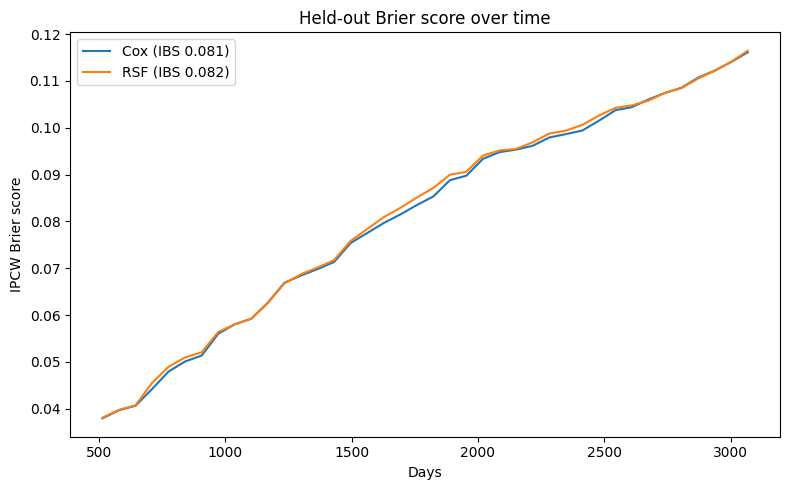

In [48]:
fig,ax=plt.subplots(figsize=(8,5))
ax.plot(cox_btime,cox_brier,label=f'Cox (IBS {cox_ibs:.3f})')
ax.plot(rsf_btime,rsf_brier,label=f'RSF (IBS {rsf_ibs:.3f})')
ax.set(xlabel='Days',ylabel='IPCW Brier score',title='Held-out Brier score over time')
ax.legend();plt.tight_layout();plt.savefig(EVAL_OUT/'brier_curves.png',dpi=150);plt.show()

## 19 — Overfitting Comparison

In [49]:
comparison=pd.DataFrame({
 'model':['Cox','RSF'], 'train_cindex':[cox_train,rsf_train],
 'cv_cindex_mean':[cox_cv['test_score'].mean(),rsf_cv['test_score'].mean()],
 'test_cindex':[cox_test,rsf_test], 'train_test_gap':[cox_train-cox_test,rsf_train-rsf_test],
 'integrated_brier':[cox_ibs,rsf_ibs]})
display(comparison)
comparison.to_csv(EVAL_OUT/'final_model_comparison.csv',index=False)

,model,train_cindex,cv_cindex_mean,test_cindex,train_test_gap,integrated_brier
0,Cox,0.797449,0.795294,0.797926,-0.000477,0.081248
1,RSF,0.826328,0.789121,0.798639,0.027689,0.081790


## 20 — Survival Probability Example

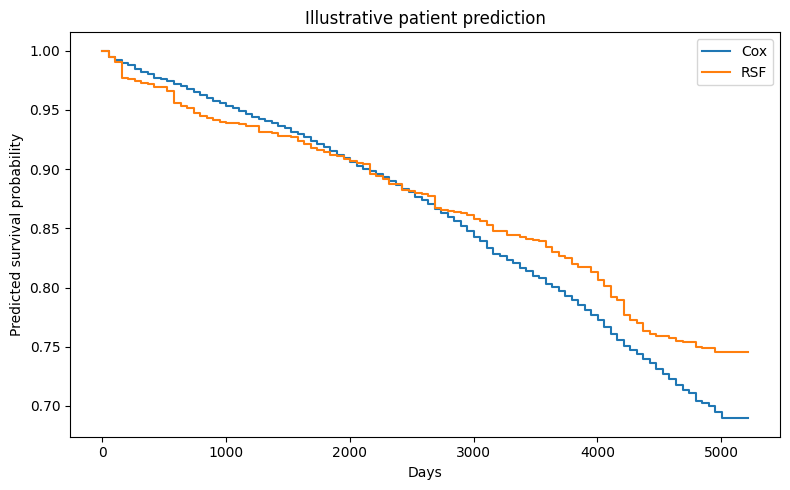

In [50]:
# Example is for illustration and is not a clinical recommendation.
example_idx=0
fig,ax=plt.subplots(figsize=(8,5))
for model,name in [(cox,'Cox'),(rsf,'RSF')]:
    curve=model.predict_survival_function(X_test.iloc[[example_idx]])[0]
    grid=np.linspace(0,min(float(np.max(y_train['time'])),float(curve.x[-1])),100)
    ax.step(grid,[float(curve(t)) for t in grid],where='post',label=name)
ax.set(xlabel='Days',ylabel='Predicted survival probability',title='Illustrative patient prediction')
ax.legend();plt.tight_layout();plt.savefig(EVAL_OUT/'example_prediction.png',dpi=150);plt.show()

## 21 — Save Models and Results

In [51]:
joblib.dump(cox,EVAL_OUT/'cox_pipeline.joblib')
joblib.dump(rsf,EVAL_OUT/'rsf_pipeline.joblib')
results={'dataset':'FLCHAIN','n_train':len(train),'n_test':len(test),
 'cox_test_cindex':cox_test,'rsf_test_cindex':rsf_test,
 'cox_cv_mean':float(cox_cv['test_score'].mean()),'rsf_cv_mean':float(rsf_cv['test_score'].mean()),
 'cox_ibs':cox_ibs,'rsf_ibs':rsf_ibs,'excluded_features':['chapter'],
 'brier_time_range_days':[float(low),float(high)]}
(EVAL_OUT/'results.json').write_text(json.dumps(results,indent=2))
print('Saved:',EVAL_OUT)

Saved: /content/outputs_flchain/notebook_03


# 04 — FLCHAIN Explainable AI & Patient Prediction


22 — Patient Survival Prediction

In [52]:

prediction_times = np.array([365, 1095, 1825])

patient_idx = 0
patient = X_test.iloc[[patient_idx]]

predictions = pd.DataFrame({
    "Time (Years)": [1, 3, 5],
    "Cox Survival Probability": [
        float(cox.predict_survival_function(patient)[0](t))
        for t in prediction_times
    ],
    "RSF Survival Probability": [
        float(rsf.predict_survival_function(patient)[0](t))
        for t in prediction_times
    ]
})

display(predictions)

predictions.to_csv(
    EVAL_OUT / "patient_survival_predictions.csv",
    index=False
)


,Time (Years),Cox Survival Probability,RSF Survival Probability
0,1,0.980144,0.971987
1,3,0.949473,0.938149
2,5,0.916333,0.913161


23 — Individual Survival Curves

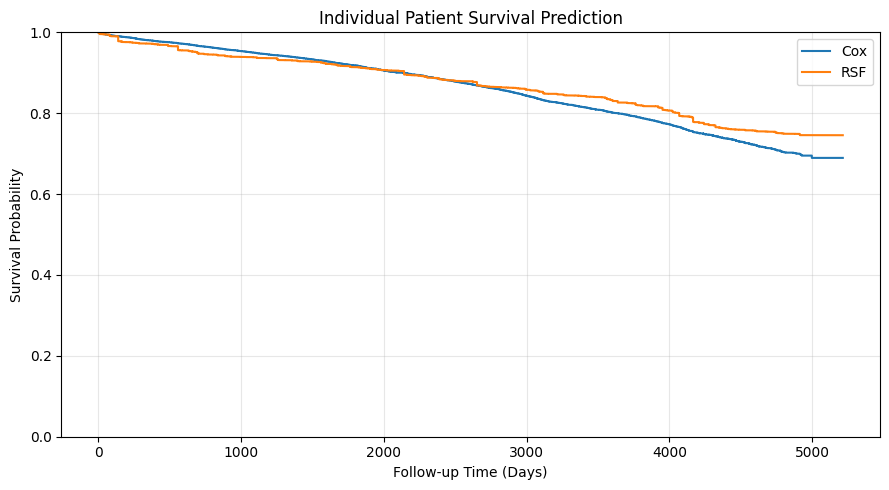

In [53]:

fig, ax = plt.subplots(figsize=(9, 5))

selected_patient = X_test.iloc[[0]]

for model, name in [(cox, "Cox"), (rsf, "RSF")]:
    curve = model.predict_survival_function(selected_patient)[0]

    ax.step(
        curve.x,
        curve.y,
        where="post",
        label=name
    )

ax.set_title("Individual Patient Survival Prediction")
ax.set_xlabel("Follow-up Time (Days)")
ax.set_ylabel("Survival Probability")
ax.set_ylim(0, 1)
ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig(EVAL_OUT / "individual_survival_curves.png", dpi=150)
plt.show()


24 — Cox Feature Contributions

,Feature,Coefficient,Hazard Ratio,Absolute Coefficient
0,numeric__age,1.110878,3.037023,1.110878
23,categorical__sample.yr_2002,-0.930969,0.394171,0.930969
21,categorical__sample.yr_2000,0.445110,1.560661,0.445110
22,categorical__sample.yr_2001,0.438536,1.550436,0.438536
13,categorical__flc.grp_10,0.364452,1.439725,0.364452
4,categorical__flc.grp_1,-0.199808,0.818888,0.199808
25,categorical__sex_F,-0.172181,0.841827,0.172181
26,categorical__sex_M,0.172181,1.187893,0.172181
3,numeric__lambda,0.144841,1.155856,0.144841
5,categorical__flc.grp_2,-0.126867,0.880851,0.126867


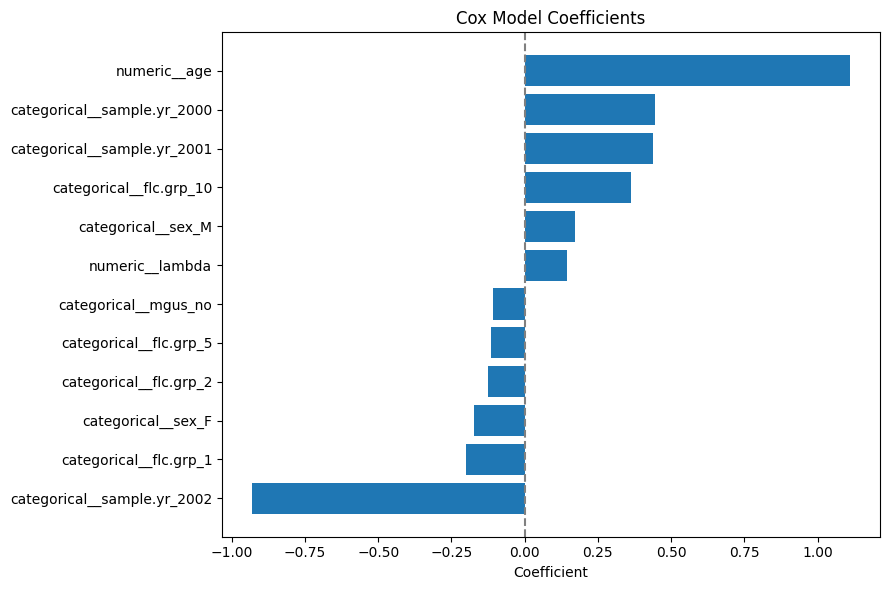

In [54]:

cox_features = cox.named_steps["preprocess"].get_feature_names_out()
cox_coefficients = cox.named_steps["model"].coef_

cox_importance = pd.DataFrame({
    "Feature": cox_features,
    "Coefficient": cox_coefficients,
    "Hazard Ratio": np.exp(cox_coefficients)
})

cox_importance["Absolute Coefficient"] = (
    cox_importance["Coefficient"].abs()
)

cox_importance = cox_importance.sort_values(
    "Absolute Coefficient",
    ascending=False
)

display(cox_importance)

cox_importance.to_csv(
    EVAL_OUT / "cox_feature_contributions.csv",
    index=False
)

fig, ax = plt.subplots(figsize=(9, 6))

top_cox = cox_importance.head(12).sort_values("Coefficient")

ax.barh(top_cox["Feature"], top_cox["Coefficient"])
ax.axvline(0, color="gray", linestyle="--")

ax.set_title("Cox Model Coefficients")
ax.set_xlabel("Coefficient")

plt.tight_layout()
plt.savefig(EVAL_OUT / "cox_feature_contributions.png", dpi=150)
plt.show()


25 — RSF Permutation Importance

,Feature,Importance,Std
0,age,0.156802,0.018335
4,lambda,0.026980,0.010108
2,flc.grp,0.023320,0.008120
3,kappa,0.022296,0.004338
1,creatinine,0.013386,0.005906
6,sample.yr,0.013386,0.003920
7,sex,0.013234,0.002148
5,mgus,-0.000011,0.000022


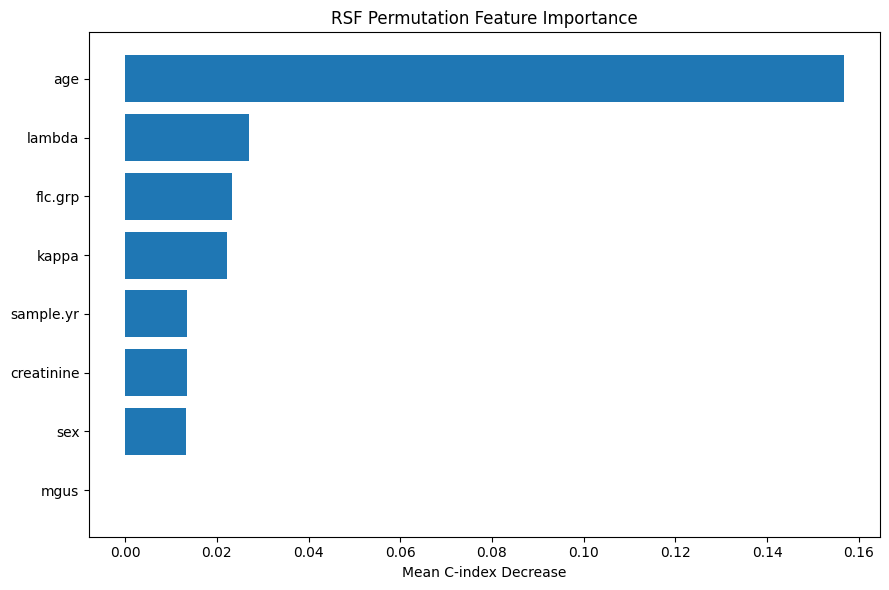

In [55]:

from sklearn.inspection import permutation_importance

# Model interpretation uses TRAINING records only; the held-out test is reserved for evaluation.
# Importance is the mean loss of training-subset C-index when an input feature is shuffled.

sample_indices = np.random.default_rng(42).choice(
    len(X_train),
    size=min(300, len(X_train)),
    replace=False
)

X_sample = X_train.iloc[sample_indices]
y_sample = y_train[sample_indices]

permutation = permutation_importance(
    rsf,
    X_sample,
    y_sample,
    scoring=None,
    n_repeats=5,
    random_state=42,
    n_jobs=1
)

rsf_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": permutation.importances_mean,
    "Std": permutation.importances_std
}).sort_values("Importance", ascending=False)

display(rsf_importance)

rsf_importance.to_csv(
    EVAL_OUT / "rsf_feature_importance.csv",
    index=False
)

fig, ax = plt.subplots(figsize=(9, 6))

plot_data = rsf_importance.sort_values("Importance")

ax.barh(
    plot_data["Feature"],
    plot_data["Importance"]
)

ax.set_title("RSF Permutation Feature Importance")
ax.set_xlabel("Mean C-index Decrease")

plt.tight_layout()
plt.savefig(EVAL_OUT / "rsf_feature_importance.png", dpi=150)
plt.show()


26 — Patient-Level Cox Explanation

,Feature,Contribution,Absolute Contribution
0,numeric__age,0.378015,0.378015
25,categorical__sex_F,-0.172181,0.172181
14,categorical__mgus_no,-0.106830,0.106830
3,numeric__lambda,0.058706,0.058706
12,categorical__flc.grp_9,0.056869,0.056869
2,numeric__kappa,0.008874,0.008874
17,categorical__sample.yr_1996,-0.003470,0.003470
1,numeric__creatinine,-0.002276,0.002276
4,categorical__flc.grp_1,-0.000000,0.000000
5,categorical__flc.grp_2,-0.000000,0.000000


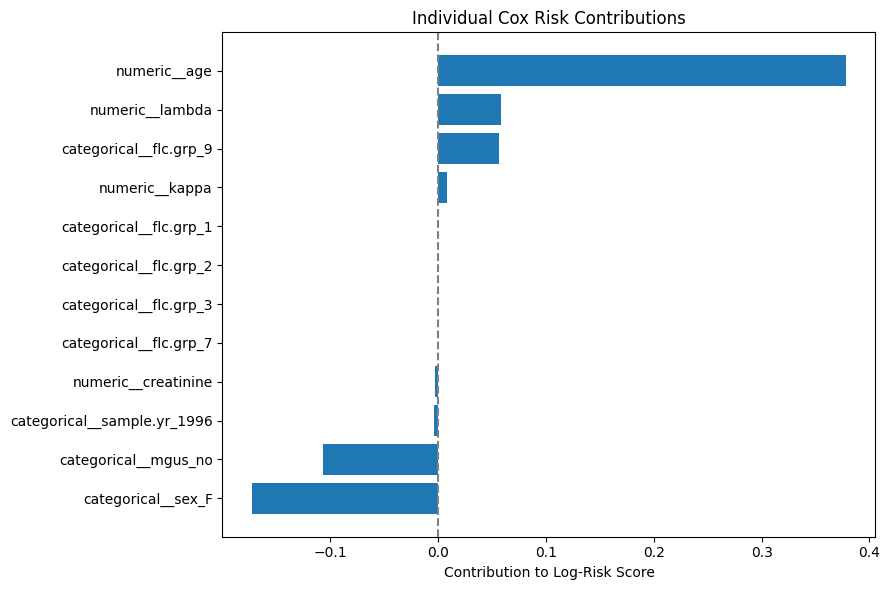

In [56]:

patient_processed = cox.named_steps["preprocess"].transform(
    X_test.iloc[[patient_idx]]
)

contributions = (
    patient_processed[0] *
    cox.named_steps["model"].coef_
)

patient_explanation = pd.DataFrame({
    "Feature": cox_features,
    "Contribution": contributions
})

patient_explanation["Absolute Contribution"] = (
    patient_explanation["Contribution"].abs()
)

patient_explanation = patient_explanation.sort_values(
    "Absolute Contribution",
    ascending=False
)

display(patient_explanation)

patient_explanation.to_csv(
    EVAL_OUT / "patient_cox_explanation.csv",
    index=False
)

fig, ax = plt.subplots(figsize=(9, 6))

top_features = patient_explanation.head(12)
top_features = top_features.sort_values("Contribution")

ax.barh(
    top_features["Feature"],
    top_features["Contribution"]
)

ax.axvline(0, color="gray", linestyle="--")
ax.set_title("Individual Cox Risk Contributions")
ax.set_xlabel("Contribution to Log-Risk Score")

plt.tight_layout()
plt.savefig(EVAL_OUT / "patient_cox_explanation.png", dpi=150)
plt.show()


27 — Risk Stratification

In [57]:

train_risk = cox.predict(X_train)
test_risk = cox.predict(X_test)

risk_thresholds = np.quantile(
    train_risk,
    [1/3, 2/3]
)

risk_groups = pd.cut(
    test_risk,
    bins=[
        -np.inf,
        risk_thresholds[0],
        risk_thresholds[1],
        np.inf
    ],
    labels=["Low", "Moderate", "High"],
    include_lowest=True
)

risk_results = pd.DataFrame({
    "Patient": np.arange(len(X_test)),
    "Risk Score": test_risk,
    "Risk Group": risk_groups
})

display(risk_results.head(10))

print(risk_results["Risk Group"].value_counts())

risk_results.to_csv(
    EVAL_OUT / "patient_risk_groups.csv",
    index=False
)


,Patient,Risk Score,Risk Group
0,0,0.217708,Moderate
1,1,-1.854060,Low
2,2,-0.542050,Moderate
3,3,-0.403768,Moderate
4,4,-0.134502,Moderate
5,5,-1.174044,Low
6,6,1.654814,High
7,7,-0.835490,Moderate
8,8,-0.299362,Moderate
9,9,-1.588105,Low


Risk Group
Low         570
Moderate    519
High        486
Name: count, dtype: int64


28 — Save Explainability Results

In [58]:

import json

explainability_summary = {
    "Dataset": "FLCHAIN",
    "Models": ["Cox Regression", "Random Survival Forest"],
    "Methods": [
        "Cox Coefficients",
        "Hazard Ratios",
        "Permutation Importance",
        "Individual Cox Contributions",
        "Survival Curves",
        "Risk Stratification"
    ],
    "Risk Thresholds": risk_thresholds.tolist(),
    "Selected Patient": int(patient_idx),
    "Prediction Times (Days)": prediction_times.tolist()
}

with open(
    EVAL_OUT / "explainability_summary.json",
    "w"
) as f:
    json.dump(explainability_summary, f, indent=4)

print("Explainability results saved successfully.")
print("Output directory:", EVAL_OUT)


Explainability results saved successfully.
Output directory: /content/outputs_flchain/notebook_03


29 — Survival Calibration Analysis

,Group,N,Predicted,Observed_KM
0,1,394,0.788966,0.764431
1,2,394,0.953272,0.954242
2,3,393,0.980999,0.979411
3,4,394,0.990791,0.984680


,Group,N,Predicted,Observed_KM
0,1,394,0.801281,0.772015
1,2,394,0.952245,0.938907
2,3,393,0.971117,0.974450
3,4,394,0.980261,0.997462


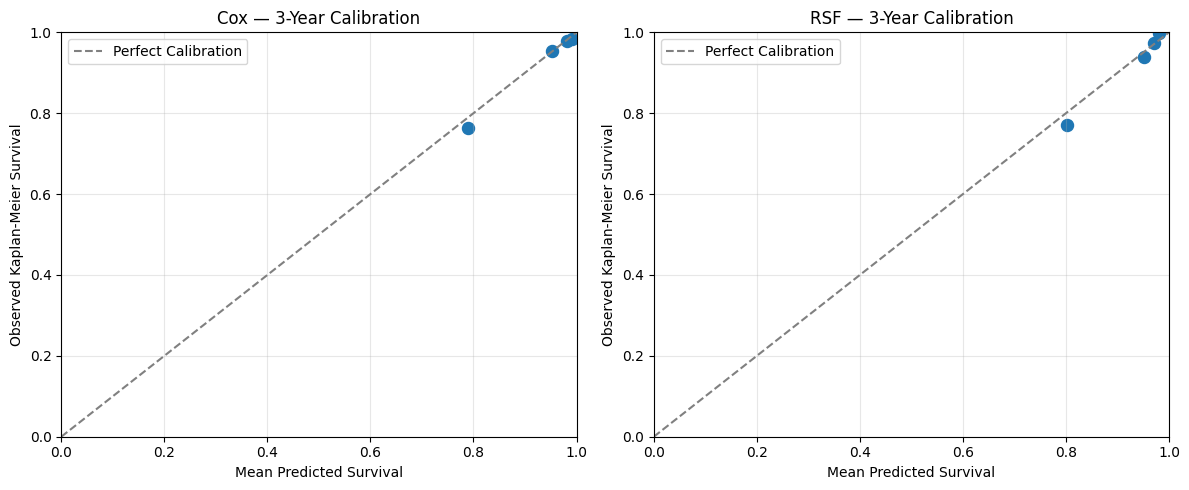

In [59]:
from lifelines import KaplanMeierFitter

calibration_time = 1095  # 3 years; fixed in advance, not selected by test performance

assert 0 < calibration_time < min(
    y_train["time"].max(),
    y_test["time"].max()
)

calibration_results = {}

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, (name, model) in zip(
    axes, [("Cox", cox), ("RSF", rsf)]
):
    survival_functions = model.predict_survival_function(X_test)

    predicted_survival = np.array([
        float(fn(calibration_time))
        for fn in survival_functions
    ])

    calibration_df = pd.DataFrame({
        "predicted": predicted_survival,
        "time": y_test["time"],
        "event": y_test["event"]
    })

    calibration_df["group"] = pd.qcut(
        calibration_df["predicted"].rank(method="first"),
        q=4,
        labels=False
    )

    rows = []

    for group, data in calibration_df.groupby("group"):
        km = KaplanMeierFitter()
        km.fit(
            durations=data["time"],
            event_observed=data["event"]
        )

        rows.append({
            "Group": int(group) + 1,
            "N": len(data),
            "Predicted": data["predicted"].mean(),
            "Observed_KM": float(
                km.survival_function_at_times(
                    calibration_time
                ).iloc[0]
            )
        })

    result = pd.DataFrame(rows)
    calibration_results[name] = result

    display(result)

    result.to_csv(
        EVAL_OUT / f"{name.lower()}_calibration.csv",
        index=False
    )

    ax.scatter(
        result["Predicted"],
        result["Observed_KM"],
        s=75
    )

    ax.plot(
        [0, 1], [0, 1],
        "--", color="gray",
        label="Perfect Calibration"
    )

    ax.set_title(f"{name} — 3-Year Calibration")
    ax.set_xlabel("Mean Predicted Survival")
    ax.set_ylabel("Observed Kaplan-Meier Survival")
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    ax.grid(alpha=0.3)
    ax.legend()

plt.tight_layout()
plt.savefig(
    EVAL_OUT / "survival_calibration.png",
    dpi=150
)
plt.show()


## 30 — Final ML Validation

In [60]:
assert np.isfinite([cox_train, rsf_train, cox_test, rsf_test, cox_ibs, rsf_ibs]).all()
assert all(0 <= v <= 1 for v in [cox_train, rsf_train, cox_test, rsf_test])
assert (EVAL_OUT / 'final_model_comparison.csv').is_file()
assert (EVAL_OUT / 'results.json').is_file()
assert (EVAL_OUT / 'survival_calibration.png').is_file()
assert (EVAL_OUT / 'rsf_feature_importance.csv').is_file()
print('Notebook 03 required outputs validated:', str(EVAL_OUT))

Notebook 03 required outputs validated: /content/outputs_flchain/notebook_03
